This is for downloading the Ogino 2026 Kaguya dataset (April 24, 2009) and attempting to recreate Ogino 2026's figure 2.


To install the dataset from Zenodo from terminal:

pip install zenodo_get zenodo_get 

17394182 -o kaguya_data

First, we look at ESA-S1 (Electron Spectrum Analyser) in Kaguya's PACE package. in High Time Resolution Mode, ESA-S1 produces a full 3D distribution every 2s covering 32 energy steps × 4 polar angles × 16 azimuthal angles. Data is already processed and split into half-sweeps (files are 1 second apart, so time resolution is doubled and energy resolution is halved) and rotated into SSE. 

In [20]:
import numpy as np

# electron mass and charge
me, e = 9.109e-31, 1.602e-19

# load data starting from 2009-04-24-22:55:24
d = np.loadtxt('kaguya_data/esa1_df_20090424225524.txt')

# load columns 0-2 as x, y, z velocity components and convert from km/s to m/s
v = d[:, :3] * 1e3

# load column 3 separately as distribution function (phase-space density) with units s^3/m^6
f = d[:, 3]

# calculate the kinetic energy of each row in eV
E = 0.5 * me * np.sum(v**2, axis=1) / e

print(d.shape) # file layout dimensions
print(E[:200].round(1)) # array of first few energies, rounded

(224, 4)
[ 24.1  39.4  63.  101.3  23.7  38.7  61.9  99.5  23.6  38.5  61.7  99.1
  23.1  37.8  60.4  97.2  24.1  39.3  62.9 101.1  23.7  38.6  61.8  99.3
  23.5  38.4  61.5  98.8  23.1  37.7  60.3  96.9  24.   39.2  62.7 100.8
  23.6  38.4  61.5  98.9  23.4  38.2  61.2  98.3  23.   37.5  60.   96.5
  23.8  38.9  62.3 100.1  23.4  38.2  61.1  98.2  23.2  37.9  60.7  97.6
  22.8  37.2  59.5  95.7  23.9  39.   62.5 100.4  23.4  38.3  61.2  98.4
  23.3  38.1  60.9  97.9  22.9  37.3  59.7  96.   23.8  38.9  62.2 100.
  23.4  38.2  61.1  98.2  23.2  37.9  60.7  97.6  22.8  37.2  59.5  95.7
  23.5  38.4  61.5  98.8  23.1  37.7  60.3  96.8  22.9  37.4  59.9  96.3
  22.5  36.8  58.8  94.5  23.6  38.5  61.5  98.9  23.1  37.7  60.4  97.1
  23.   37.6  60.1  96.6  22.6  36.9  59.   94.8  23.5  38.4  61.5  98.8
  23.1  37.7  60.3  96.9  22.9  37.4  59.9  96.2  22.5  36.7  58.8  94.5
  23.8  38.9  62.2 100.   23.3  38.1  61.   98.   23.2  37.9  60.6  97.5
  22.8  37.2  59.5  95.6  23.8  38.9  62.2 

For this file, we obtain that there are 224 rows with 4 energies, around 24, 38, 62 and 98 eV. Therefore there are 224/4 = 56 outlook directions (out of 64... why are 8 missing?). Therefore the instrument bins electrons into these four steps.

Now attempt to recreate Fig 2 from Ogino 2025. Looking at LMAG data for magnetic field:

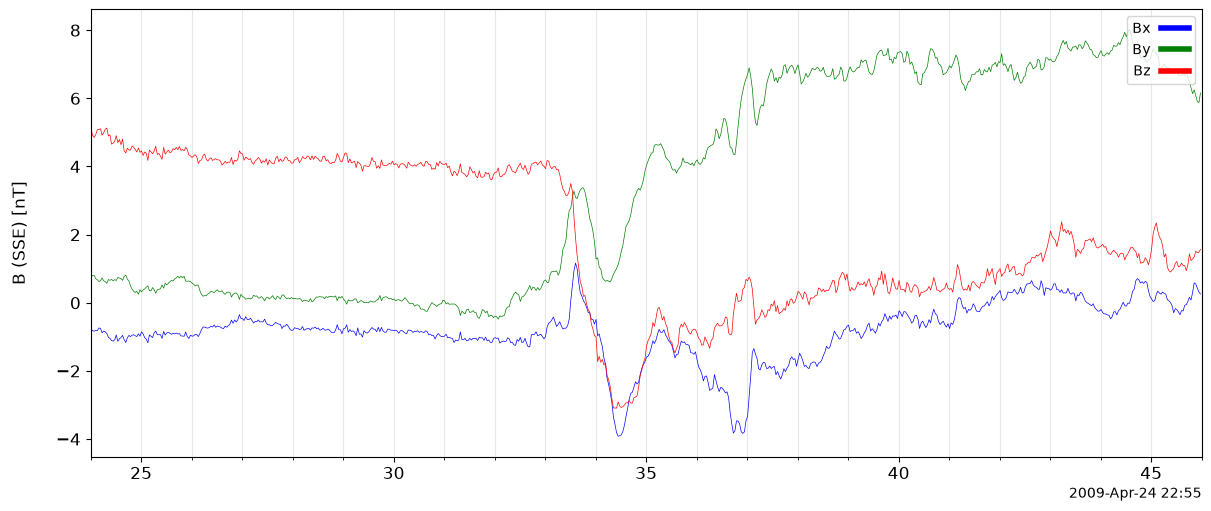

In [21]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from pyspedas import time_double, store_data, tplot, options

fn = 'kaguya_data/lmag_32Hz_Bsse_20090424225120-20090424230400.txt'
tstr = np.loadtxt(fn, usecols=0, dtype=str) # column 0: time string
B = np.loadtxt(fn, usecols=(1, 2, 3)) # columns 1, 2, 3: Bx, By, Bz (nT)
t = np.array(time_double(tstr))

store_data('kgy_lmag_sse', data={'x': t, 'y': B})
options('kgy_lmag_sse', 'legend_names', ['Bx', 'By', 'Bz'])
options('kgy_lmag_sse', 'ytitle', 'B (SSE) [nT]')

fig, ax = tplot('kgy_lmag_sse',
                trange=['2009-04-24/22:55:24', '2009-04-24/22:55:46'],
                display=False, return_plot_objects=True)

ax.xaxis.set_minor_locator(mdates.SecondLocator())   # a tick every second
ax.grid(which='both', axis='x', alpha=0.3)           # vertical grid lines on all ticks
plt.show()

recall that store_data creates a tplot variable, where time array is paired with data array and stored in pySPEDAS memory under some name. options attaches plotting settings to stored variable.

Add also total B magnitude:

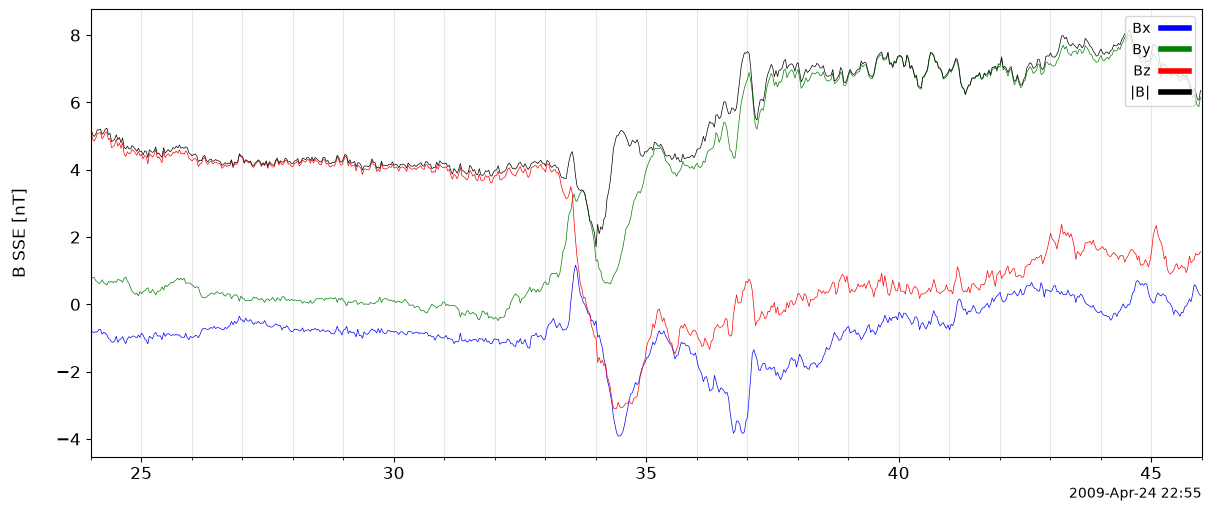

In [22]:
Bmag = np.linalg.norm(B, axis=1) #average across each row 
Ball = np.column_stack([B, Bmag])

store_data('kgy_lmag_sse_all', data={'x': t, 'y': Ball})
options('kgy_lmag_sse_all', 'legend_names', ['Bx', 'By', 'Bz', '|B|'])
options('kgy_lmag_sse_all', 'ytitle', 'B SSE [nT]')

fig, ax = tplot('kgy_lmag_sse_all',
                trange=['2009-04-24/22:55:24', '2009-04-24/22:55:46'],
                display=False, return_plot_objects=True)

ax.xaxis.set_minor_locator(mdates.SecondLocator())
ax.grid(which='both', axis='x', alpha=0.3)
plt.show()

Ogino et al. suggest that the |B| dip is correlated with field rotation and the Bx spike around 37 s is correlated with the flux rope. We also observe the strong perturbed field after the flux rope. 

Next we attempt to plot the same B field rotated to LMN coordinates (N: normal to sheet, L: along sheet, M: orthogonal third axis out of the plane along which current flows). The paper builds the coordinates using the cross-product method. First we determine the shearing angle between B1 (field before sheet) and B2 (field after the sheet):

In [28]:
# define sampling window for some range [t0, t1] and calculate mean Bx, y, z
def window_mean(t, B, t0, t1):
    m = (t >= time_double(t0)) & (t < time_double(t1))
    return B[m].mean(axis=0)

#set B1 and B2 as B values just before and after (guessed interval, paper not stated)
B1 = window_mean(t, B, '2009-04-24/22:55:31.5', '2009-04-24/22:55:32.0')
B2 = window_mean(t, B, '2009-04-24/22:55:39.0', '2009-04-24/22:55:39.5')

# find shearing angle before two fields: 
cos_shear = B1 @ B2 / (np.linalg.norm(B1) * np.linalg.norm(B2))
shear = np.degrees(np.arccos(cos_shear))

# normalise orthogonal N vector:
N = np.cross(B1, B2)
N = N / np.linalg.norm(N)

print('B1:', B1.round(2), ' B2', B2.round(2))
print('shear:', shear.round(2), 'deg')
print('N:', N.round(2))

B1: [-1.07 -0.32  3.77]  B2 [-0.82  6.9   0.51]
shear: 88.8 deg
N: [-0.96 -0.09 -0.28]


We obtain a shear angle of 88.8 degrees and an N vector of [-0.96 -0.09 -0.28]. This matches the paper closely, and variance probably comes from difference in window choice.

Now we find L with minimum variance analysis.

Using a lagrangian multiplier to maximise variance, we obtain an EVP and find that each e-value is the variance along the corresponding e-vector:

In [34]:
m = (t >= time_double('2009-04-24/22:55:32')) & (t < time_double('2009-04-24/22:55:39'))
Bcs = B[m] # samples inside the crossing

dB = Bcs - Bcs.mean(axis=0) # subtract the mean field: B - <B>
M_cov = dB.T @ dB / len(dB) # covariance matrix: M_jk = <dB_j dB_k>

lam, vec = np.linalg.eigh(M_cov) # eigenvalues and eigenvectors
L_mva = vec[:, -1] # eigenvector with the largest eigenvalue

L_cross_N = np.cross(L_mva, N)

print('eigenvalue:', lam.round(3))
print('L_mva:', L_mva.round(2))
print('cross product with N:', L_cross_N)
print('ratio mid/min:', (lam[1] / lam[0]).round(1))

eigenvalue: [0.613 3.068 7.424]
L_mva: [-0.17  0.79 -0.59]
cross product with N: [-0.27549831  0.52084832  0.76728776]
ratio mid/min: 5.0


We find eigenvalues [0.613 3.068 7.424]. The field varies most along the 7.4 eigenvector. we obtain a mid / min ratio of 5, so the field varied 5 times more along mid direction than min. This means that the axes are distinguishable. We obtain an L vector of [-0.17  0.79 -0.59]. This is not perfectly perpendicular to N (else cross product would be 0), so we correct it to be inside the sheet by taking another cross product.

We build the third direction M by crossing N with L_mva, and then build the corrected L by crossing M with N:

In [36]:
M_ax = np.cross(N, L_mva)
M_ax = M_ax / np.linalg.norm(M_ax)
L_ax = np.cross(M_ax, N)

if (B1 @ L_ax) < 0: # sign convention: B_L positive before the sheet and negative after
    L_ax, M_ax = -L_ax, -M_ax

print('L:', L_ax.round(2))
print('M:', M_ax.round(2))
print('N:', N.round(2))

L: [-0.08 -0.84  0.54]
M: [-0.28  0.54  0.79]
N: [-0.96 -0.09 -0.28]


Having obtained the LMN axes, we rotate the field into the new axes and plot rotated field:

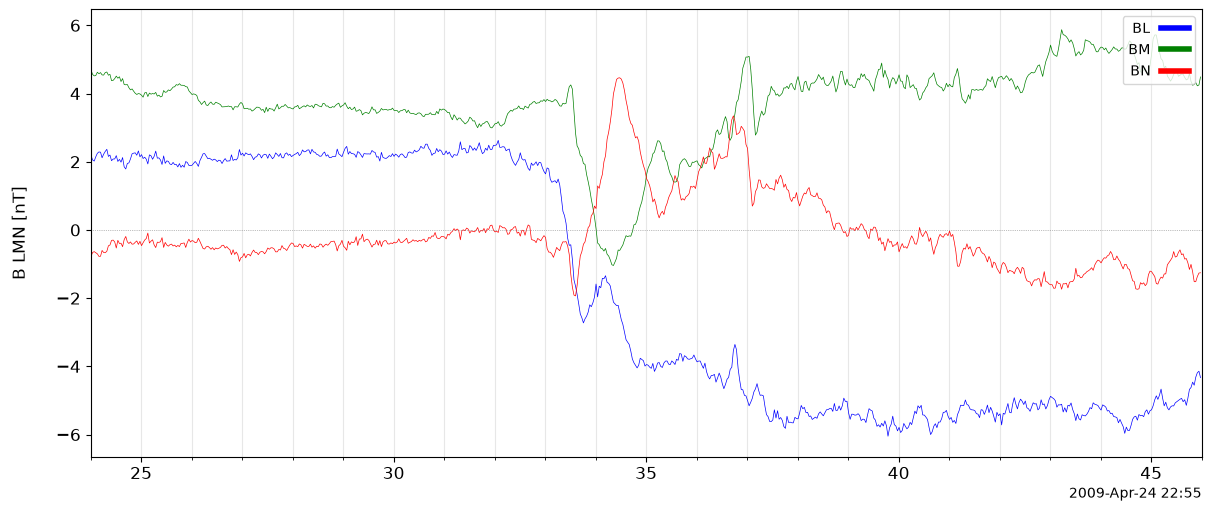

In [46]:
R = np.vstack([L_ax, M_ax, N]) # 3x3 rotation matrix with stacked vectors L, M, N as rows
B_lmn = B @ R.T # each row becomes [B·L, B·M, B·N]

store_data('kgy_lmag_lmn', data={'x': t, 'y': B_lmn})
options('kgy_lmag_lmn', 'legend_names', ['BL', 'BM', 'BN'])
options('kgy_lmag_lmn', 'color', ['b', 'g', 'r'])
options('kgy_lmag_lmn', 'ytitle', 'B LMN [nT]')

fig, ax = tplot('kgy_lmag_lmn',
                trange=['2009-04-24/22:55:24', '2009-04-24/22:55:46'],
                display=False, return_plot_objects=True)
ax.axhline(0, color='grey', lw=0.5, ls=':') 
ax.xaxis.set_minor_locator(mdates.SecondLocator())
ax.grid(which='both', axis='x', alpha=0.3)
plt.show()

B_L changes sign, suggesting crossing occured.

Now plotting electron energy spectrogram using ESA-S2:

(24,) (24, 14) (24, 14)


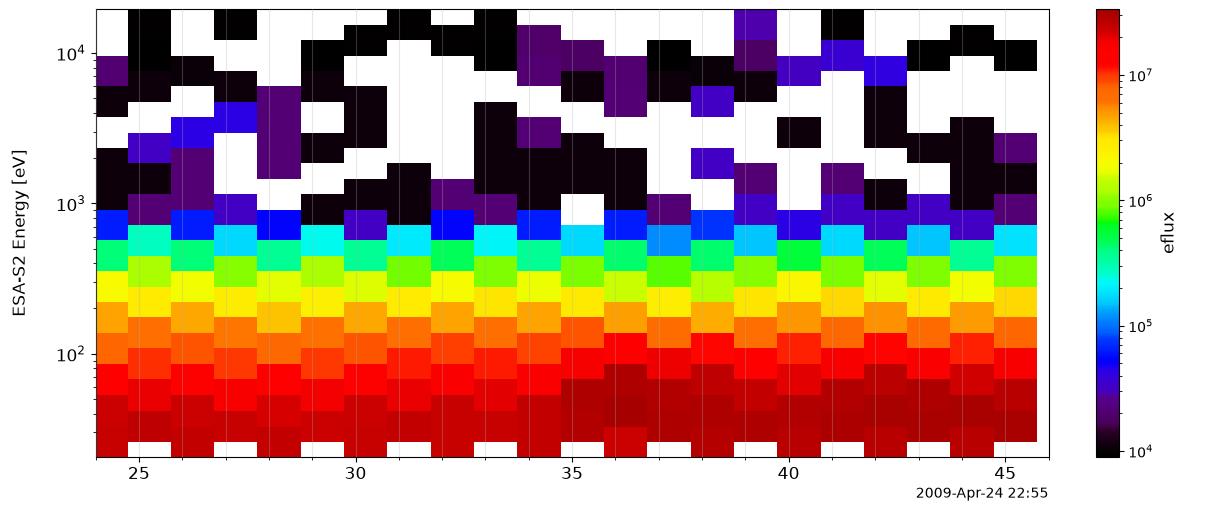

In [51]:
import glob

f_ef = glob.glob('kaguya_data/esa2_eflux*')[0]
f_en = glob.glob('kaguya_data/esa2_energy*')[0]

t_e    = np.array(time_double(np.loadtxt(f_ef, usecols=0, dtype=str)))
eflux  = np.loadtxt(f_ef, usecols=range(1, 15))
energy = np.loadtxt(f_en)
eflux[eflux <= 0] = np.nan

print(t_e.shape, eflux.shape, energy.shape)

store_data('kgy_esa2_eflux', data={'x': t_e, 'y': eflux, 'v': energy})
options('kgy_esa2_eflux', 'spec', True)
options('kgy_esa2_eflux', 'ylog', True)
options('kgy_esa2_eflux', 'zlog', True)
options('kgy_esa2_eflux', 'ytitle', 'ESA-S2 Energy [eV]')
options('kgy_esa2_eflux', 'ztitle', 'eflux')


fig, axes = tplot('kgy_esa2_eflux',
                  trange=['2009-04-24/22:55:24', '2009-04-24/22:55:46'],
                  display=False, return_plot_objects=True)

for ax in np.atleast_1d(axes):
    ax.xaxis.set_minor_locator(mdates.SecondLocator())
    ax.grid(which='both', axis='x', alpha=0.3)
    ax.set_axisbelow(False)
plt.show()